# FinBERT CNN baseline and hard sentences

1. Train the CNN on frozen FinBERT word-piece embeddings (our main small model).
2. Get a probability for every sentence: out-of-fold for train, from the baseline for val and test.
3. Mark the **hard** sentences: the top probability is between 0.4 and 0.6.
4. Mark the **all-agree** sentences: every annotator gave the same label.
5. Train the same CNN with fine-tuned FinBERT embeddings (for RQ2).

The hard sets are saved in `results/hard_samples/band_*.csv` and used by the targeted training notebooks.

### Load required packages

In [21]:
import os

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import keras
from keras.models import Sequential
from keras.layers import Input, Embedding, Dense, Dropout, SpatialDropout1D, Conv1D, GlobalMaxPooling1D
from keras.optimizers import Adam
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping, Callback

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import StratifiedKFold

# FinBERT is downloaded into the project folder
os.environ["HF_HOME"] = os.path.abspath("../.cache/huggingface")
os.environ["HF_HUB_CACHE"] = os.path.abspath("../.cache/huggingface/hub")
from transformers import BertModel, BertTokenizerFast

# Fix the random seed
keras.utils.set_random_seed(42)

/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1108 17:49:44.831000 70005 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


### Loading the dataset

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

LABELS = ["negative", "neutral", "positive"]
y_train = train_df.label.map({"negative": 0, "neutral": 1, "positive": 2}).values
y_val = val_df.label.map({"negative": 0, "neutral": 1, "positive": 2}).values
y_test = test_df.label.map({"negative": 0, "neutral": 1, "positive": 2}).values
print(len(train_df), len(val_df), len(test_df))

2901 967 968


### FinBERT tokens and embeddings

The sentences are split into FinBERT word pieces (max 64), and we take FinBERT's embedding matrix: one 768-number vector per word piece.

In [3]:
tokenizer = BertTokenizerFast.from_pretrained("yiyanghkust/finbert-pretrain")
X_train = tokenizer(list(train_df.sentence), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]
X_val = tokenizer(list(val_df.sentence), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]
X_test = tokenizer(list(test_df.sentence), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]

finbert = BertModel.from_pretrained("yiyanghkust/finbert-pretrain")
embedding_matrix = finbert.embeddings.word_embeddings.weight.detach().numpy()
del finbert
print(X_train.shape, X_val.shape, X_test.shape, embedding_matrix.shape)

/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1105 10:30:11.360000 11358 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 40363.00it/s]
[transformers] BertModel LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | U

(2901, 64) (967, 64) (968, 64) (30873, 768)


model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

In [4]:
i = 0
print(train_df.sentence[i])
print(tokenizer.convert_ids_to_tokens(X_train[i][:20]))

The fair value of the company 's investment properties went down to EUR 2.768 billion at the end of 2009 from EUR 2.916 billion a year earlier .
['[CLS]', 'the', 'fair', 'value', 'of', 'the', 'company', "'", 's', 'investment', 'properties', 'went', 'down', 'to', 'eur', '2', '.', '76', '##8', 'billion']


### The CNN

Embedding (FinBERT) -> SpatialDropout 0.3 -> Conv1D (64 filters, width 3) -> global max pooling -> Dense 32 -> Dropout 0.5 -> softmax.
After every epoch we compute macro F1 on val, so early stopping can use it (Keras only has accuracy and loss built in).

In [4]:
early_stop = EarlyStopping(monitor="val_macro_f1", mode="max", patience=5, restore_best_weights=True)
history = baseline_model.fit(X_train, to_categorical(y_train, 3),
                             validation_data=(X_val, to_categorical(y_val, 3)),
                             epochs=20, batch_size=32, callbacks=[MacroF1(), early_stop])

Epoch 1/20
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5882 - loss: 0.9495 - val_macro_f1: 0.3184
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5888 - loss: 0.9485 - val_accuracy: 0.6236 - val_loss: 0.8556 - val_macro_f1: 0.3184
Epoch 2/20
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6399 - loss: 0.8319 - val_macro_f1: 0.4151
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6412 - loss: 0.8309 - val_accuracy: 0.6784 - val_loss: 0.7745 - val_macro_f1: 0.4151
Epoch 3/20
87/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6832 - loss: 0.7568 - val_macro_f1: 0.4368
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6880 - loss: 0.7501 - val_accuracy: 0.6939 - val_loss: 0.7141 - val_macro_f1: 0.4368
Epoch 4/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7218 - loss: 0.6512 - val_macro_f1: 0.5897
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7218 - loss: 0.6512 - val_accuracy: 0.7332 - val_loss: 0.6519 - val_macro_f1: 0.5897
Epoch 5/20
8

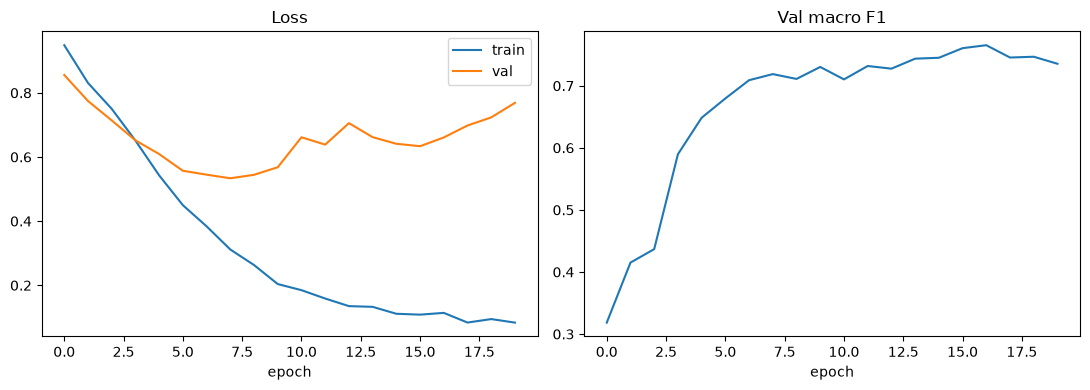

In [9]:
# visualise training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history.history["loss"], label="train")
ax1.plot(history.history["val_loss"], label="val")
ax1.set_title("Loss")
ax1.set_xlabel("epoch")
ax1.legend()
ax2.plot(history.history["val_macro_f1"])
ax2.set_title("Val macro F1")
ax2.set_xlabel("epoch")
plt.tight_layout()
plt.show()

In [ ]:
val_probabilities = baseline_model.predict(X_val, batch_size=32, verbose=0)
test_probabilities = baseline_model.predict(X_test, batch_size=32, verbose=0)
print("val macro F1:", round(f1_score(y_val, val_probabilities.argmax(axis=1), average="macro"), 4))
print(classification_report(y_val, val_probabilities.argmax(axis=1), target_names=LABELS))

val macro F1: 0.7653
              precision    recall  f1-score   support

    negative       0.85      0.61      0.71       121
     neutral       0.84      0.88      0.86       574
    positive       0.72      0.74      0.73       272

    accuracy                           0.80       967
   macro avg       0.80      0.74      0.77       967
weighted avg       0.81      0.80      0.80       967



## 2. Out-of-fold probabilities on train

The baseline has seen every train sentence, so it is too sure about them. Instead we split train into 5 parts:
each part is predicted by a model trained on the other 4 parts, so every train sentence gets an honest probability.

In [15]:
oof_probabilities = np.zeros((len(y_train), 3))
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold_train, fold_test in folds.split(X_train, y_train):
    fold_model = build_cnn(trainable=False)
    early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    fold_model.fit(X_train[fold_train], to_categorical(y_train[fold_train], 3),
                   validation_split=0.1, epochs=20, batch_size=32, verbose=0, callbacks=[early_stop])
    oof_probabilities[fold_test] = fold_model.predict(X_train[fold_test], batch_size=32, verbose=0)

print("out-of-fold macro F1:", round(f1_score(y_train, oof_probabilities.argmax(axis=1), average="macro"), 4))

{'train':                                                sentence     label  p_negative  \
 0     The fair value of the company 's investment pr...  negative    0.903733   
 1     Trading under the name Velta UK , a former Upo...   neutral    0.026475   
 2     Via the move , the company aims annual savings...  positive    0.144699   
 3     The company also estimates the already carried...  positive    0.013724   
 4     However , the proportion of the paid standing ...  positive    0.001686   
 ...                                                 ...       ...         ...   
 2896  The event can also be viewed as a live webcast...   neutral    0.002633   
 2897  Finnish waste management and cleaning group La...  negative    0.938475   
 2898  4 ) Complete name of the shareholder : Otto He...   neutral    0.012595   
 2899  Global Markets Direct 's Pohjola Bank plc - Fi...   neutral    0.002357   
 2900  Metso will supply the equipment for two proces...  positive    0.010960   
 
     

## 3. Hard sentences: confidence band

A sentence is hard when the top probability is between 0.4 and 0.6, so the model does not clearly choose a class.

In [16]:
def make_table(df, probabilities):
    out = df[["sentence", "label"]].copy()
    out["p_negative"] = probabilities[:, 0]
    out["p_neutral"] = probabilities[:, 1]
    out["p_positive"] = probabilities[:, 2]
    out["pred"] = [LABELS[i] for i in probabilities.argmax(axis=1)]
    out["max_prob"] = probabilities.max(axis=1)
    out["is_hard"] = (out.max_prob >= 0.4) & (out.max_prob <= 0.6)
    return out

band_train = make_table(train_df, oof_probabilities)
band_val = make_table(val_df, val_probabilities)
band_test = make_table(test_df, test_probabilities)

print("hard train:", band_train.is_hard.sum(), "/", len(band_train))
print("hard val:  ", band_val.is_hard.sum(), "/", len(band_val))
print("hard test: ", band_test.is_hard.sum(), "/", len(band_test))

Band: [0.400, 0.600]
train: hard=364 / 2901  (below band: 10)
val: hard=47 / 967  (below band: 2)
test: hard=50 / 968  (below band: 1)


## 4. All-agree sentences

`data/Sentences_AllAgree.txt` (from the original Financial PhraseBank) has the sentences where all annotators gave the same label. One `sentence@label` per line, latin-1 encoding.

In [19]:
summary = []
for name, out in [("train", band_train), ("val", band_val), ("test", band_test)]:
    summary.append({"split": name, "rows": len(out), "hard": out.is_hard.sum(),
                    "all-agree": out.all_agree.sum(),
                    "hard & all-agree": (out.is_hard & out.all_agree).sum(),
                    "% all-agree (hard)": round(100 * out[out.is_hard].all_agree.mean(), 1),
                    "% all-agree (non-hard)": round(100 * out[~out.is_hard].all_agree.mean(), 1)})
summary = pd.DataFrame(summary)
summary

,rows,hard,all-agree,hard & all-agree,% all-agree (hard),% all-agree (non-hard)
train,2901,364,1327,103,28.3%,48.2%
val,967,47,448,14,29.8%,47.2%
test,968,50,437,14,28.0%,46.1%


- hard: the top probability is between 0.4 and 0.6 (364 rows in train, 47 in val, 50 in test).
- all-agree: every annotator gave the same label, so people found the sentence clear (about 46% of each split).
- hard and all-agree: the model is unsure, but people were not.

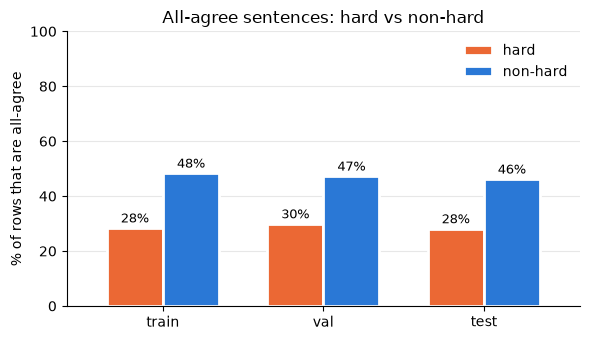

In [22]:
x = np.arange(3)
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.2, summary["% all-agree (hard)"], width=0.4, label="hard", color="#eb6834")
plt.bar(x + 0.2, summary["% all-agree (non-hard)"], width=0.4, label="non-hard", color="#2a78d6")
plt.xticks(x, summary.split)
plt.ylim(0, 100)
plt.ylabel("% of rows that are all-agree")
plt.title("All-agree sentences: hard vs non-hard")
plt.legend()
plt.tight_layout()
plt.savefig("../results/figures/band_all_agree.png", dpi=150)
plt.show()

Save the tables. The targeted training uses these files, so a file that already exists is **not** overwritten (delete it yourself if you really want to make a new hard set).

In [ ]:
os.makedirs("../results/hard_samples", exist_ok=True)
for name, out in [("train", band_train), ("val", band_val), ("test", band_test)]:
    path = "../results/hard_samples/band_" + name + ".csv"
    if os.path.exists(path):
        print(path, "already exists, not overwritten")
    else:
        out.to_csv(path, index=False)
        print("saved", path)

saved band_train.csv (2901, 9)
saved band_val.csv (967, 9)
saved band_test.csv (968, 9)


## 5. FinBERT fine-tuned (for RQ2)

Same CNN and seed, but the FinBERT embeddings are trained too (23.7M extra parameters). Only used for the metrics, the hard sets stay the ones from the frozen model.
Slow: ~10 minutes.

In [24]:
hard = pd.read_csv("../results/hard_samples/band_val.csv").is_hard.values

def metrics_row(probs, embedding_config):
    pred = probs.argmax(axis=1)
    per_class = f1_score(y_val, pred, labels=[0, 1, 2], average=None)
    return {"condition": "baseline", "embedding_config": embedding_config, "architecture": "cnn_64",
            "accuracy_overall": accuracy_score(y_val, pred),
            "f1_overall": f1_score(y_val, pred, average="macro"),
            "accuracy_hard": accuracy_score(y_val[hard], pred[hard]),
            "f1_hard": f1_score(y_val[hard], pred[hard], average="macro"),
            "accuracy_nonhard": accuracy_score(y_val[~hard], pred[~hard]),
            "f1_nonhard": f1_score(y_val[~hard], pred[~hard], average="macro"),
            "f1_negative": per_class[0], "f1_neutral": per_class[1], "f1_positive": per_class[2]}

Same CNN and seed, but the FinBERT embeddings are trained too. It only gets a metrics row; the hard mask stays the one from the frozen model.

condition    embedding_config         architecture  accuracy_overall  \
0         targeted   finbert_finetuned               cnn_64          0.778697   
1         targeted      finbert_frozen               cnn_64          0.798345   
2         targeted  finbert_pretrained  transformer_finbert          0.857438   
3   random_control   finbert_finetuned               cnn_64          0.779731   
4   random_control      finbert_frozen               cnn_64          0.798759   
5    llm_benchmark         native_qwen  qwen2.5-7b-instruct          0.776600   
6         baseline       tfidf_1-2gram               logreg          0.776629   
7         baseline    random_init_100d      lstm_64_dropout          0.698035   
8         baseline       random_frozen               cnn_64          0.741468   
9         baseline    random_finetuned               cnn_64          0.783868   
10        baseline      finbert_frozen               cnn_64          0.804550   

    f1_overall  accuracy_hard   f1_hard  accuracy_nonhard  f1_nonhard  \
0     0.709929       0.552577  0.477068          0.803908    0.741177   
1     0.749777       0.624742  0.451130          0.817701    0.770973   
2     0.838963       0.582474  0.560134               NaN         NaN   
3     0.710225       0.538776  0.466455          0.806904    0.743418   
4     0.749278       0.618367  0.455547          0.819102    0.771809   
5     0.786000       0.666700  0.674300          0.797300    0.808500   
6     0.717241       0.474227  0.390474          0.810345    0.760566   
7     0.464626       0.453608  0.319597          0.725287    0.480581   
8     0.659704       0.422680  0.365168          0.777011    0.697802   
9     0.706000       0.536082  0.415473          0.811494    0.745897   
10    0.765318       0.595745  0.605812          0.815217    0.772013   

    f1_negative  f1_neutral  f1_positive  
0      0.601528    0.847326     0.680935  
1      0.686379    0.853857     0.709095  
2           NaN         NaN          NaN  
3      0.597771    0.847918     0.684985  
4      0.683070    0.854425     0.710340  
5      0.837400    0.793800     0.726700  
6      0.631579    0.845771     0.674374  
7      0.000000    0.832653     0.561224  
8      0.545455    0.824096     0.609562  
9      0.580645    0.849725     0.687631  
10     0.711538    0.857143     0.727273

In [ ]:
keras.utils.set_random_seed(BASELINE_SEED)
finetuned_model = train_baseline(embedding_matrix, X_train, y_train, X_val, y_val, trainable=True, verbose=0,
                                 epochs=80)   # trainable embeddings learn slowly at lr 5e-5: ~40 epochs, 20 is not enough
finetuned_probabilities = finetuned_model.predict(X_val, batch_size=32, verbose=0)

metrics = pd.read_csv("../results/metrics.csv")
metrics = pd.concat([metrics, pd.DataFrame(rows)], ignore_index=True)
metrics = metrics.drop_duplicates(subset=["condition", "embedding_config", "architecture"], keep="last")
metrics.to_csv("../results/metrics.csv", index=False)
pd.DataFrame(rows)[["embedding_config", "accuracy_overall", "f1_overall", "f1_hard"]].round(3)